In [1]:
import matplotlib.pyplot as plt
import cv2
import os

# Compter les images
train_images = len(os.listdir('../data/train/images'))
valid_images = len(os.listdir('../data/valid/images'))
test_images = len(os.listdir('../data/test/images'))

print(f"📊 STATISTIQUES SIMPLES:")
print(f"Train: {train_images} images")
print(f"Valid: {valid_images} images")
print(f"Test: {test_images} images")

# Question 1: Est-ce équilibré ?
# Réponse attendue: ~70% train, 15% valid, 15% test
total = train_images + valid_images + test_images
print(f"Train: {train_images/total*100:.0f}%")
print(f"Valid: {valid_images/total*100:.0f}%")
print(f"Test: {test_images/total*100:.0f}%")

📊 STATISTIQUES SIMPLES:
Train: 1054 images
Valid: 123 images
Test: 123 images
Train: 81%
Valid: 9%
Test: 9%


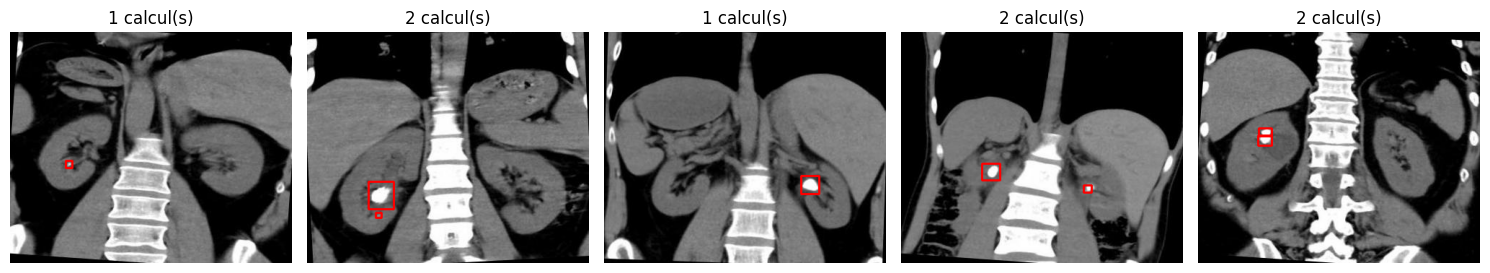

In [2]:
# Vérifier que les boîtes sont correctes
import random

# Prenez 5 images au hasard
sample_images = random.sample(os.listdir('../data/train/images'), 5)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for idx, img_name in enumerate(sample_images):
    # Charger image
    img_path = f'../data/train/images/{img_name}'
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Charger label correspondant
    label_name = img_name.replace('.jpg', '.txt').replace('.png', '.txt')
    label_path = f'../data/train/labels/{label_name}'
    
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            annotations = f.readlines()
        
        # Dessiner chaque boîte
        for ann in annotations:
            class_id, x_center, y_center, width, height = map(float, ann.split())
            
            # Convertir YOLO vers pixels
            h, w = img.shape[:2]
            x1 = int((x_center - width/2) * w)
            y1 = int((y_center - height/2) * h)
            x2 = int((x_center + width/2) * w)
            y2 = int((y_center + height/2) * h)
            
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
    
    axes[idx].imshow(img)
    axes[idx].set_title(f"{len(annotations)} calcul(s)" if annotations else "0 calcul")
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

# Question 2: Les boîtes sont-elles bien placées ?
# Réponse: Vérifiez visuellement

In [6]:
# Répondez par oui/non dans votre tête :

print("🔍 CHECKLIST QUALITÉ DONNÉES:")
print("1. Toutes les images sont-elles de bonne qualité ? → ", end="")
print("✅" if input_qualite else "❌")

print("2. Les calculs sont-ils bien entourés ? → ", end="")
print("✅" if input_bbox else "❌")

print("3. Y a-t-il assez d'images (min 500) ? → ", end="")
print("✅" if total > 500 else "❌")

print("4. Les formats sont-ils cohérents (jpg/png) ? → ", end="")
print("✅" if formats_ok else "❌")

🔍 CHECKLIST QUALITÉ DONNÉES:
1. Toutes les images sont-elles de bonne qualité ? → 

NameError: name 'input_qualite' is not defined